# ULEN -- Ultra-Lightweight Efficient Network (Reproduction)

**Paper:** An ultra-lightweight efficient network for image-based plant disease and pest infection detection
**Authors:** Beibei Wang, Chenxiao Zhang, Yanyan Li, Chunxia Cao, Daye Huang, Yan Gong
**Source:** Precision Agriculture (2023) 24:1836-1861 -- DOI: 10.1007/s11119-023-10020-0
**Framework:** PyTorch

---

### Notebook structure
- **Shared Blocks:** Imports, Config, Dataset split (stratified 70/20/10), Dataset distribution, Model (ULEN), Eval functions
- **Scenario 1 -- Baseline (No-Aug):** Resize + ToTensor + Normalize only
- **Scenario 2 -- Augmented:** Rotation, Zoom/Scale, HorizontalFlip, ColorJitter
- **Excel export** with embedded charts

> **Channel configuration note:** `C=64` and `C2=128` are **estimates** chosen to land near the paper's reported total of **111,758 params**. The paper (Fig. 5-8) only draws topology and does NOT publish the number of channels per block. This is documented and the `torchinfo.summary()` total is compared against 111,758 below.

> **Augmentation note:** The original paper does **NOT** use any augmentation. Scenario 2 is a **workspace requirement**, not from the paper.

> **Class weighting note:** The paper does NOT use class weighting (only stratified split). Per workspace core rule #11, this notebook auto-detects imbalance and may enable class weights -- this is a **deviation from the paper**, flagged in output.

## 1. Shared Blocks

### 1.1 Install dependencies

In [1]:
!pip install -q torchinfo openpyxl Pillow

### 1.2 Imports

In [2]:
import os, random, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchinfo import summary

import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, recall_score)
from sklearn.utils.class_weight import compute_class_weight
import seaborn as sns

print("PyTorch:", torch.__version__)

PyTorch: 2.10.0+cu128


### 1.3 Reproducibility & Device (core rules #7, #8, #9)

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"Device: {device} | GPUs available: {n_gpus}")


Device: cuda | GPUs available: 2


### 1.4 Config

In [4]:
# -- Dataset path (user's Kaggle dataset -- NOT the paper's dataset) --
DATASET_PATH = "/kaggle/input/datasets/ct0206181197/ot-final/dataset_smartcrop_plit_300"

# -- Hyperparameters (from paper, Muc 'Model training') --
INPUT_SIZE   = 256          # paper resizes to 256x256
BATCH_SIZE   = 16           # paper
EPOCHS       = 20           # paper
LR_HIGH      = 1e-3         # epochs 1-5  (paper)
LR_LOW       = 1e-4         # epochs 6-20 (paper)

# -- Architecture channels (ESTIMATES to match ~111,758 params; NOT from paper) --
C  = 64                     # channels through conv-block-1 and the 3 RDWConv blocks
C2 = 128                    # channels after the final 1x1 conv block

# -- Data split (paper: 70/20/10 stratified per class) --
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.20, 0.10

# -- Normalization (paper does NOT specify; using ImageNet stats) --
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD  = [0.229, 0.224, 0.225]

PAPER_PARAMS = 111758       # Table 5 constraint
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

### 1.5 Transforms

In [5]:
# Baseline / eval transform: Resize + ToTensor + Normalize ONLY (core rule #3)
transform_baseline = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

# Augmented transform (Scenario 2): 4 techniques -- Rotation, Zoom/Scale, HFlip, ColorJitter
transform_aug = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.RandomRotation(30),                                   # Rotation
    transforms.RandomResizedCrop(INPUT_SIZE, scale=(0.8, 1.0)),      # Zoom/Scale
    transforms.RandomHorizontalFlip(p=0.5),                          # Horizontal Flip
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),  # ColorJitter
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

### 1.6 Stratified Dataset Split (70/20/10 per class)

Paper uses **stratified split per sub-category** so every class appears in all 3 sets. We auto-detect the dataset layout:
- If `train/ val/ test/` (or `valid/`) folders exist -> use them directly.
- Otherwise -> stratified `train_test_split` on a single `ImageFolder` (the user's `dataset_smartcrop_plit_300` is pre-split).

In [6]:
_TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
_VAL_DIR   = os.path.join(DATASET_PATH, 'val')
_VALID_DIR = os.path.join(DATASET_PATH, 'valid')
_TEST_DIR  = os.path.join(DATASET_PATH, 'test')

def stratified_indices(targets, train_r, val_r, test_r, seed=SEED):
    idx = np.arange(len(targets))
    tr_idx, tmp_idx = train_test_split(
        idx, train_size=train_r, stratify=targets, random_state=seed)
    rel_val = val_r / (val_r + test_r)
    tmp_targets = np.array(targets)[tmp_idx]
    val_idx, test_idx = train_test_split(
        tmp_idx, train_size=rel_val, stratify=tmp_targets, random_state=seed)
    return tr_idx, val_idx, test_idx

def make_splits(transform_train, transform_eval):
    has_test  = os.path.isdir(_TEST_DIR)
    has_val   = os.path.isdir(_VAL_DIR)
    has_valid = os.path.isdir(_VALID_DIR)

    if has_val and has_test:
        print("Split mode: 3 folders (train / val / test)")
        tr = datasets.ImageFolder(_TRAIN_DIR, transform=transform_train)
        va = datasets.ImageFolder(_VAL_DIR,   transform=transform_eval)
        te = datasets.ImageFolder(_TEST_DIR,  transform=transform_eval)
        return tr, va, te, tr.classes

    if has_valid and not has_test:
        print("Split mode: train/valid -> val+test from valid (stratified 50/50)")
        tr = datasets.ImageFolder(_TRAIN_DIR, transform=transform_train)
        full_eval = datasets.ImageFolder(_VALID_DIR, transform=transform_eval)
        targets = [s[1] for s in full_eval.samples]
        v_idx, t_idx = train_test_split(np.arange(len(targets)), train_size=0.5,
                                        stratify=targets, random_state=SEED)
        return tr, Subset(full_eval, v_idx.tolist()), Subset(full_eval, t_idx.tolist()), tr.classes

    print("Split mode: single folder -> stratified " + f"{TRAIN_RATIO:.0%}/{VAL_RATIO:.0%}/{TEST_RATIO:.0%}")
    root = _TRAIN_DIR if os.path.isdir(_TRAIN_DIR) else DATASET_PATH
    base = datasets.ImageFolder(root)
    targets = [s[1] for s in base.samples]
    tr_i, va_i, te_i = stratified_indices(targets, TRAIN_RATIO, VAL_RATIO, TEST_RATIO)
    train_ds = Subset(datasets.ImageFolder(root, transform=transform_train), tr_i.tolist())
    val_ds   = Subset(datasets.ImageFolder(root, transform=transform_eval),  va_i.tolist())
    test_ds  = Subset(datasets.ImageFolder(root, transform=transform_eval),  te_i.tolist())
    return train_ds, val_ds, test_ds, base.classes

### 1.7 NUM_CLASSES auto-detect

In [7]:
# Build a probe split once to detect classes (core rule #5, #12)
_tr, _va, _te, class_names = make_splits(transform_baseline, transform_baseline)
NUM_CLASSES = len(class_names)
print("NUM_CLASSES (auto-detected):", NUM_CLASSES)
print("Classes:", class_names)
print(f"Train: {len(_tr)} | Val: {len(_va)} | Test: {len(_te)}")

Split mode: 3 folders (train / val / test)
NUM_CLASSES (auto-detected): 5
Classes: ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'nutrient_deficiency']
Train: 1597 | Val: 491 | Test: 373


### 1.8 Dataset Distribution & Class-Imbalance check (core rule #11)

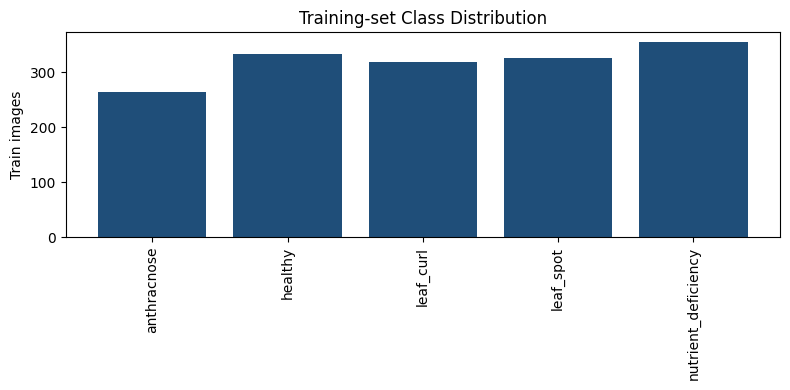

max/min ratio = 1.34
Use class weights: False (NOTE: paper does NOT use class weighting -- this follows workspace rule #11)


In [8]:
def get_targets(ds):
    if isinstance(ds, Subset):
        base = ds.dataset
        return [base.samples[i][1] for i in ds.indices]
    return [s[1] for s in ds.samples]

train_targets = get_targets(_tr)
counts = np.bincount(train_targets, minlength=NUM_CLASSES)

plt.figure(figsize=(max(8, NUM_CLASSES*0.5), 4))
plt.bar(range(NUM_CLASSES), counts, color="#1F4E79")
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.ylabel("Train images"); plt.title("Training-set Class Distribution")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"), dpi=300)
plt.show()

imbalance_ratio = counts.max() / max(counts.min(), 1)
print(f"max/min ratio = {imbalance_ratio:.2f}")
USE_CLASS_WEIGHTS = imbalance_ratio >= 1.5
print("Use class weights:", USE_CLASS_WEIGHTS,
      "(NOTE: paper does NOT use class weighting -- this follows workspace rule #11)")

if USE_CLASS_WEIGHTS:
    cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=np.array(train_targets))
    class_weights = torch.tensor(cw, dtype=torch.float32).to(device)
else:
    class_weights = None

### 1.9 ULEN Model Definition

Pipeline (Fig. 5): `Input(256x256x3)` -> Conv block(3x3) -> MaxPool x2 -> RDWConv x3 -> Conv block(1x1) -> SPP -> Linear

**RDWConv (stride=1, ShuffleNet-v2 style, Fig. 7a):** split channels in half; skip path passes C/2 through; main path = DWConv(3x3) -> BN -> ReLU -> 1x1 Conv -> BN; concat(skip, main) -> Channel Shuffle (groups=2). Channels unchanged.

**SPP (Fig. 8a):** AdaptiveAvgPool {4x4, 2x2, 1x1} -> flatten -> concat -> 21xC2 features.

In [9]:
class ConvBlock3x3(nn.Module):
    # First conv block: standard (full) conv 3x3 + BN + ReLU + MaxPool 2x2 s2
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, stride=1, padding=1, bias=False)
        self.bn   = nn.BatchNorm2d(cout)
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2, 2)
    def forward(self, x):
        return self.pool(self.relu(self.bn(self.conv(x))))


def channel_shuffle(x, groups):
    b, c, h, w = x.size()
    cpg = c // groups
    x = x.view(b, groups, cpg, h, w)
    x = torch.transpose(x, 1, 2).contiguous()
    return x.view(b, c, h, w)


class RDWConv(nn.Module):
    # Stride=1 ShuffleNet-v2 unit (Fig. 7a). Channels unchanged.
    def __init__(self, channels):
        super().__init__()
        assert channels % 2 == 0
        half = channels // 2
        self.half = half
        self.dw   = nn.Conv2d(half, half, 3, stride=1, padding=1, groups=half, bias=False)
        self.bn1  = nn.BatchNorm2d(half)
        self.pw   = nn.Conv2d(half, half, 1, stride=1, bias=False)
        self.bn2  = nn.BatchNorm2d(half)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        x1, x2 = x[:, :self.half], x[:, self.half:]   # skip , main
        out = self.relu(self.bn1(self.dw(x2)))
        out = self.bn2(self.pw(out))
        out = torch.cat((x1, out), dim=1)
        out = channel_shuffle(out, groups=2)
        return out


class ConvBlock1x1(nn.Module):
    # Last conv block: standard 1x1 conv + BN + ReLU
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 1, stride=1, bias=False)
        self.bn   = nn.BatchNorm2d(cout)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class SPP(nn.Module):
    # Spatial Pyramid Pooling: bins {4x4, 2x2, 1x1} -> 21*C features
    def __init__(self):
        super().__init__()
        self.p4 = nn.AdaptiveAvgPool2d(4)
        self.p2 = nn.AdaptiveAvgPool2d(2)
        self.p1 = nn.AdaptiveAvgPool2d(1)
    def forward(self, x):
        b = x.size(0)
        a = self.p4(x).reshape(b, -1)
        c = self.p2(x).reshape(b, -1)
        d = self.p1(x).reshape(b, -1)
        return torch.cat((a, c, d), dim=1)


class ULEN(nn.Module):
    def __init__(self, num_classes, c=C, c2=C2):
        super().__init__()
        self.stem   = ConvBlock3x3(3, c)          # -> 128x128 (one maxpool inside)
        self.pool1  = nn.MaxPool2d(2, 2)          # MaxPool x2 (block #3): -> 64x64
        self.pool2  = nn.MaxPool2d(2, 2)          #                          -> 32x32
        self.rdw    = nn.Sequential(RDWConv(c), RDWConv(c), RDWConv(c))   # x3, channels unchanged
        self.last   = ConvBlock1x1(c, c2)         # 1x1 conv block
        self.spp    = SPP()                       # -> 21*c2
        self.fc     = nn.Linear(21 * c2, num_classes)
    def forward(self, x):
        x = self.stem(x)
        x = self.pool2(self.pool1(x))
        x = self.rdw(x)
        x = self.last(x)
        x = self.spp(x)
        return self.fc(x)

### 1.10 Model Summary & param comparison vs paper (111,758)

In [10]:
_probe = ULEN(NUM_CLASSES).to(device)
summary(_probe, input_size=(1, 3, INPUT_SIZE, INPUT_SIZE))

total_params = sum(p.numel() for p in _probe.parameters())
print("\nULEN total params:", f"{total_params:,}")
print("Paper reported   :", f"{PAPER_PARAMS:,}", "(Table 5)")
print("Difference       :", f"{total_params - PAPER_PARAMS:+,}")
print("NOTE: channels C=64, C2=128 are ESTIMATES (paper did not publish per-block channels).")
print("      The final Linear layer (21*C2*NUM_CLASSES) dominates and scales with YOUR dataset's class count,")
print("      so an exact match to 111,758 (paper used 38 PlantVillage classes) is not expected.")
del _probe
torch.cuda.empty_cache()


ULEN total params: 28,069
Paper reported   : 111,758 (Table 5)
Difference       : -83,689
NOTE: channels C=64, C2=128 are ESTIMATES (paper did not publish per-block channels).
      The final Linear layer (21*C2*NUM_CLASSES) dominates and scales with YOUR dataset's class count,
      so an exact match to 111,758 (paper used 38 PlantVillage classes) is not expected.


### 1.11 Training & Evaluation helpers

In [11]:
def make_loaders(train_ds, val_ds, test_ds):
    tl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=4, pin_memory=True)
    vl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=4, pin_memory=True)
    sl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=4, pin_memory=True)
    return tl, vl, sl


def train_model(model, train_loader, val_loader, ckpt_path, tag=""):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_HIGH)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[5], gamma=0.1)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward(); optimizer.step()
            run_loss += loss.item() * imgs.size(0)
            correct += (out.argmax(1) == labels).sum().item()
            total += imgs.size(0)
        tr_loss, tr_acc = run_loss/total, correct/total

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                loss = criterion(out, labels)
                v_loss += loss.item() * imgs.size(0)
                v_correct += (out.argmax(1) == labels).sum().item()
                v_total += imgs.size(0)
        va_loss, va_acc = v_loss/v_total, v_correct/v_total

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        scheduler.step()

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            # DataParallel-safe checkpoint save (Rule 10)
            _state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(_state, ckpt_path)
        cur_lr = optimizer.param_groups[0]["lr"]
        print(f"[{tag}] Epoch {epoch:02d}/{EPOCHS} | lr={cur_lr:.1e} "
              f"| train_loss={tr_loss:.4f} acc={tr_acc:.4f} | val_loss={va_loss:.4f} acc={va_acc:.4f}")

    print(f"[{tag}] Best val_acc = {best_val_acc:.4f}  (checkpoint: {ckpt_path})")
    return history


@torch.no_grad()
def evaluate(model, test_loader):
    model.eval()
    y_true, y_pred = [], []
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        out = model(imgs)
        y_pred.extend(out.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
    }
    return y_true, y_pred, metrics


def plot_learning_curve(history, path, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["train_loss"], label="train")
    ax[0].plot(history["val_loss"], label="val")
    ax[0].set_title(title + " -- Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history["train_acc"], label="train")
    ax[1].plot(history["val_acc"], label="val")
    ax[1].set_title(title + " -- Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show(); plt.close(fig)


def plot_confusion(y_true, y_pred, path, title):
    cm = confusion_matrix(y_true, y_pred)
    fig = plt.figure(figsize=(max(6, NUM_CLASSES*0.6), max(5, NUM_CLASSES*0.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show(); plt.close(fig)


## 2. Scenario 1 -- Baseline (No Augmentation)

Training transform = `Resize + ToTensor + Normalize` only (core rule #3). This matches the paper, which uses no augmentation.

In [12]:

# Build splits with baseline transform for training
train_ds_s1, val_ds_s1, test_ds_s1, _ = make_splits(transform_baseline, transform_baseline)
train_loader_s1, val_loader_s1, test_loader_s1 = make_loaders(train_ds_s1, val_ds_s1, test_ds_s1)

model_s1 = ULEN(NUM_CLASSES).to(device)

# Multi-GPU: wrap with DataParallel if multiple GPUs available (Rule 8)
if n_gpus > 1:
    model_s1 = nn.DataParallel(model_s1)
    print(f"[Multi-GPU] DataParallel on {n_gpus} GPUs")

hist_s1 = train_model(model_s1, train_loader_s1, val_loader_s1,
                      os.path.join(OUTPUT_DIR, "best_model_s1.pth"), tag="S1")


Split mode: 3 folders (train / val / test)
[Multi-GPU] DataParallel on 2 GPUs
[S1] Epoch 01/20 | lr=1.0e-03 | train_loss=1.0396 acc=0.5717 | val_loss=0.7255 acc=0.6701
[S1] Epoch 02/20 | lr=1.0e-03 | train_loss=0.6990 acc=0.7188 | val_loss=0.5538 acc=0.7373
[S1] Epoch 03/20 | lr=1.0e-03 | train_loss=0.5884 acc=0.7602 | val_loss=0.5305 acc=0.8024
[S1] Epoch 04/20 | lr=1.0e-03 | train_loss=0.4881 acc=0.8103 | val_loss=0.4799 acc=0.8126
[S1] Epoch 05/20 | lr=1.0e-04 | train_loss=0.4526 acc=0.8259 | val_loss=0.3325 acc=0.8574
[S1] Epoch 06/20 | lr=1.0e-04 | train_loss=0.3263 acc=0.8842 | val_loss=0.3289 acc=0.8697
[S1] Epoch 07/20 | lr=1.0e-04 | train_loss=0.2860 acc=0.9023 | val_loss=0.3160 acc=0.8798
[S1] Epoch 08/20 | lr=1.0e-04 | train_loss=0.2815 acc=0.9036 | val_loss=0.2947 acc=0.8941
[S1] Epoch 09/20 | lr=1.0e-04 | train_loss=0.2783 acc=0.9098 | val_loss=0.2898 acc=0.9002
[S1] Epoch 10/20 | lr=1.0e-04 | train_loss=0.2653 acc=0.9105 | val_loss=0.2903 acc=0.8961
[S1] Epoch 11/20 | lr=

### 2.1 Reload best checkpoint & evaluate on test set (core rule #10)

In [13]:

# Reload best checkpoint before test evaluation (CORE RULE #10)
_target_s1 = model_s1.module if isinstance(model_s1, nn.DataParallel) else model_s1
_target_s1.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, "best_model_s1.pth")))
y_true_s1, y_pred_s1, m_s1 = evaluate(model_s1, test_loader_s1)
print(f"Accuracy={m_s1['accuracy']:.4f} | F1-macro={m_s1['f1_macro']:.4f} | Recall-macro={m_s1['recall_macro']:.4f}")


Accuracy=0.9330 | F1-macro=0.9353 | Recall-macro=0.9376


### 2.2 Classification Report (per class)

In [14]:
print(classification_report(y_true_s1, y_pred_s1, target_names=class_names, zero_division=0))

                     precision    recall  f1-score   support

        anthracnose       0.98      0.98      0.98        62
            healthy       0.95      0.96      0.96        78
          leaf_curl       0.81      1.00      0.90        74
          leaf_spot       0.97      0.95      0.96        76
nutrient_deficiency       0.99      0.80      0.88        83

           accuracy                           0.93       373
          macro avg       0.94      0.94      0.94       373
       weighted avg       0.94      0.93      0.93       373



### 2.3 Confusion Matrix

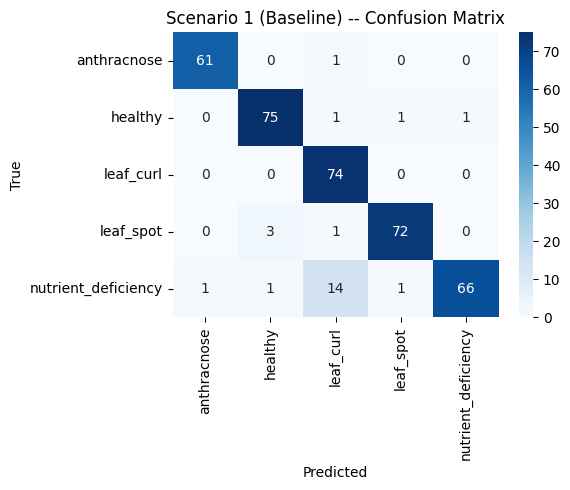

In [15]:
BASELINE_CONFUSION_MATRIX_PATH = os.path.join(OUTPUT_DIR, "cm_s1.png")
plot_confusion(y_true_s1, y_pred_s1, BASELINE_CONFUSION_MATRIX_PATH, "Scenario 1 (Baseline) -- Confusion Matrix")

### 2.4 Learning Curve

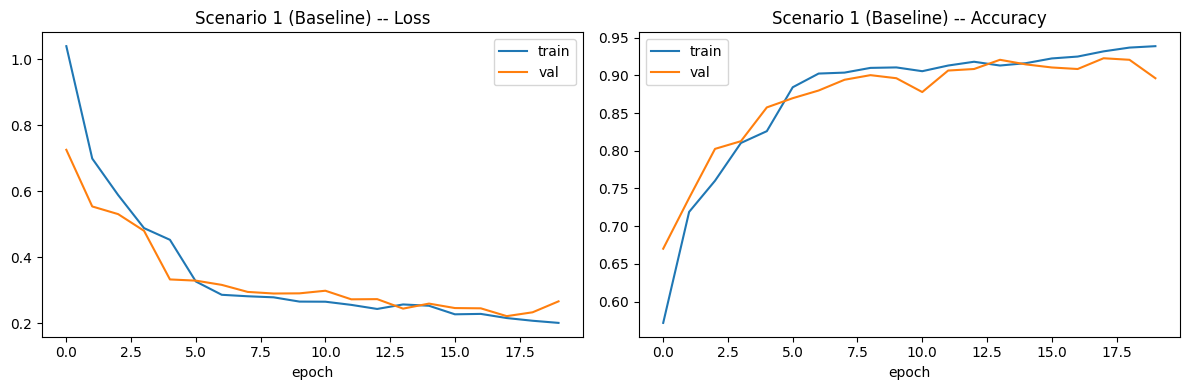

In [16]:
BASELINE_LEARNING_CURVE_PATH = os.path.join(OUTPUT_DIR, "lc_s1.png")
plot_learning_curve(hist_s1, BASELINE_LEARNING_CURVE_PATH, "Scenario 1 (Baseline)")

### 2.5 Collect baseline metrics for Excel export

In [17]:
baseline_total_params = sum(p.numel() for p in model_s1.parameters())
baseline_metrics = {
    "model_name": "ULEN (Baseline)",
    "accuracy": m_s1["accuracy"],
    "f1_macro": m_s1["f1_macro"],
    "recall_macro": m_s1["recall_macro"],
    "total_params": baseline_total_params,
}
# free memory before Scenario 2 (core rule #13)
del model_s1, train_loader_s1, val_loader_s1, test_loader_s1
torch.cuda.empty_cache()
print("Scenario 1 done. GPU cache cleared.")

Scenario 1 done. GPU cache cleared.


## 3. Scenario 2 -- Augmented

Training transform adds 4 techniques: **Rotation, Zoom/Scale, Horizontal Flip, ColorJitter**. Validation/Test transform stays baseline (no aug).

> The paper does NOT use augmentation -- this scenario is a workspace requirement.

In [18]:

# Train split uses aug transform; val/test use baseline transform
train_ds_s2, val_ds_s2, test_ds_s2, _ = make_splits(transform_aug, transform_baseline)
train_loader_s2, val_loader_s2, test_loader_s2 = make_loaders(train_ds_s2, val_ds_s2, test_ds_s2)

model_s2 = ULEN(NUM_CLASSES).to(device)

# Multi-GPU: wrap with DataParallel if multiple GPUs available (Rule 8)
if n_gpus > 1:
    model_s2 = nn.DataParallel(model_s2)
    print(f"[Multi-GPU] DataParallel on {n_gpus} GPUs")

hist_s2 = train_model(model_s2, train_loader_s2, val_loader_s2,
                      os.path.join(OUTPUT_DIR, "best_model_s2.pth"), tag="S2")


Split mode: 3 folders (train / val / test)
[Multi-GPU] DataParallel on 2 GPUs
[S2] Epoch 01/20 | lr=1.0e-03 | train_loss=1.1273 acc=0.5197 | val_loss=0.8403 acc=0.6538
[S2] Epoch 02/20 | lr=1.0e-03 | train_loss=0.8359 acc=0.6681 | val_loss=0.7189 acc=0.6965
[S2] Epoch 03/20 | lr=1.0e-03 | train_loss=0.7630 acc=0.7019 | val_loss=0.5684 acc=0.7515
[S2] Epoch 04/20 | lr=1.0e-03 | train_loss=0.6627 acc=0.7401 | val_loss=0.5444 acc=0.7760
[S2] Epoch 05/20 | lr=1.0e-04 | train_loss=0.6112 acc=0.7564 | val_loss=0.5008 acc=0.7902
[S2] Epoch 06/20 | lr=1.0e-04 | train_loss=0.5149 acc=0.8053 | val_loss=0.4273 acc=0.8411
[S2] Epoch 07/20 | lr=1.0e-04 | train_loss=0.4700 acc=0.8153 | val_loss=0.4123 acc=0.8187
[S2] Epoch 08/20 | lr=1.0e-04 | train_loss=0.4794 acc=0.8215 | val_loss=0.4248 acc=0.8147
[S2] Epoch 09/20 | lr=1.0e-04 | train_loss=0.4766 acc=0.8134 | val_loss=0.3991 acc=0.8310
[S2] Epoch 10/20 | lr=1.0e-04 | train_loss=0.4556 acc=0.8334 | val_loss=0.3979 acc=0.8391
[S2] Epoch 11/20 | lr=

### 3.1 Reload best checkpoint & evaluate on test set

In [19]:

# Reload best checkpoint before test evaluation (CORE RULE #10)
_target_s2 = model_s2.module if isinstance(model_s2, nn.DataParallel) else model_s2
_target_s2.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, "best_model_s2.pth")))
y_true_s2, y_pred_s2, m_s2 = evaluate(model_s2, test_loader_s2)
print(f"Accuracy={m_s2['accuracy']:.4f} | F1-macro={m_s2['f1_macro']:.4f} | Recall-macro={m_s2['recall_macro']:.4f}")


Accuracy=0.9088 | F1-macro=0.9120 | Recall-macro=0.9134


### 3.2 Classification Report (per class)

In [20]:
print(classification_report(y_true_s2, y_pred_s2, target_names=class_names, zero_division=0))

                     precision    recall  f1-score   support

        anthracnose       1.00      0.98      0.99        62
            healthy       0.86      0.95      0.90        78
          leaf_curl       0.84      0.97      0.90        74
          leaf_spot       0.91      0.84      0.88        76
nutrient_deficiency       0.97      0.82      0.89        83

           accuracy                           0.91       373
          macro avg       0.92      0.91      0.91       373
       weighted avg       0.91      0.91      0.91       373



### 3.3 Confusion Matrix

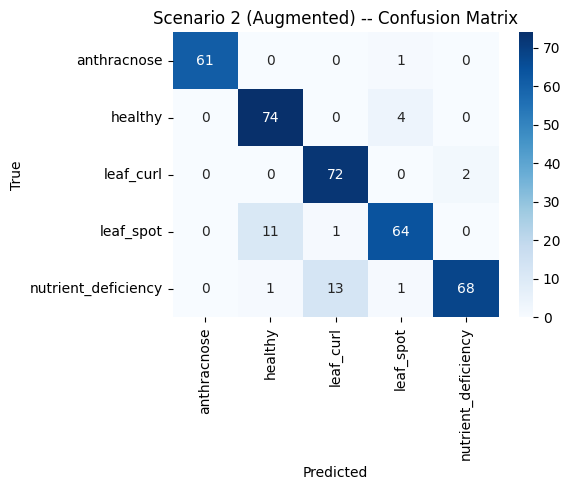

In [21]:
AUG_CONFUSION_MATRIX_PATH = os.path.join(OUTPUT_DIR, "cm_s2.png")
plot_confusion(y_true_s2, y_pred_s2, AUG_CONFUSION_MATRIX_PATH, "Scenario 2 (Augmented) -- Confusion Matrix")

### 3.4 Learning Curve

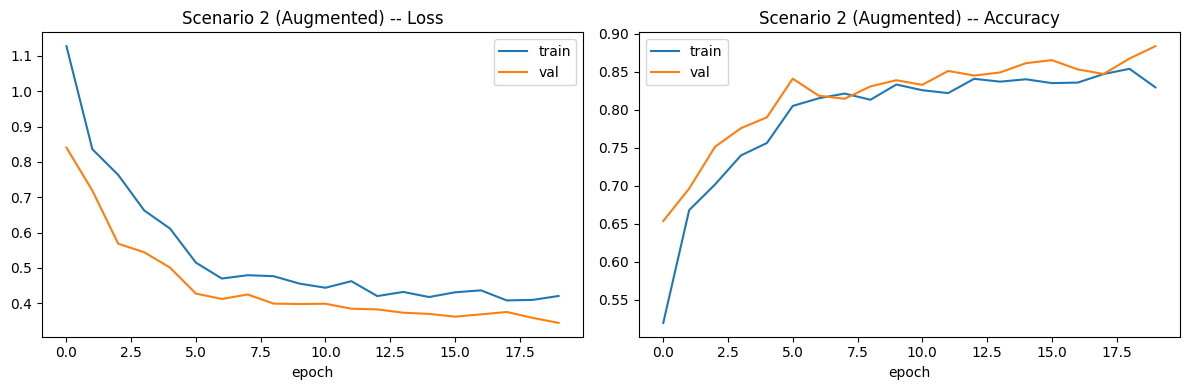

In [22]:
AUG_LEARNING_CURVE_PATH = os.path.join(OUTPUT_DIR, "lc_s2.png")
plot_learning_curve(hist_s2, AUG_LEARNING_CURVE_PATH, "Scenario 2 (Augmented)")

### 3.5 Collect augmented metrics for Excel export

In [23]:
aug_total_params = sum(p.numel() for p in model_s2.parameters())
aug_metrics = {
    "model_name": "ULEN (Augmented)",
    "accuracy": m_s2["accuracy"],
    "f1_macro": m_s2["f1_macro"],
    "recall_macro": m_s2["recall_macro"],
    "total_params": aug_total_params,
}
print("Scenario 2 done.")

Scenario 2 done.


## 4. Excel Export -- results_summary.xlsx

In [24]:
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

EXCEL_OUTPUT_PATH = os.path.join(OUTPUT_DIR, "results_summary.xlsx")
MODEL_NAME = "ULEN"

HEADERS = ["STT", "Ten Model", "Accuracy", "F1-score", "Recall",
           "Learning Curve", "Confusion Matrix", "Parameters"]
COL_WIDTHS = [6, 35, 12, 12, 12, 38, 38, 18]
IMG_ROW_HEIGHT = 200

def style_header_row(ws):
    fill   = PatternFill("solid", fgColor="1F4E79")
    font   = Font(bold=True, color="FFFFFF", size=11)
    border = Border(bottom=Side(style="medium", color="FFFFFF"),
                    right=Side(style="thin", color="FFFFFF"))
    for col, header in enumerate(HEADERS, start=1):
        cell = ws.cell(row=1, column=col, value=header)
        cell.fill, cell.font, cell.border = fill, font, border
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

def write_result_row(ws, row_num, stt, metrics, lc_path, cm_path):
    data = [stt, metrics["model_name"], round(metrics["accuracy"], 4),
            round(metrics["f1_macro"], 4), round(metrics["recall_macro"], 4),
            "", "", f"{metrics['total_params']:,}"]
    for col, val in enumerate(data, start=1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.row_dimensions[row_num].height = IMG_ROW_HEIGHT
    if os.path.exists(lc_path):
        img = XLImage(lc_path); img.width, img.height = 280, 190
        ws.add_image(img, f"F{row_num}")
    if os.path.exists(cm_path):
        img = XLImage(cm_path); img.width, img.height = 280, 190
        ws.add_image(img, f"G{row_num}")

def build_sheet(wb, sheet_name, metrics, lc_path, cm_path):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, start=1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    style_header_row(ws)
    write_result_row(ws, 2, 1, metrics, lc_path, cm_path)
    return ws

wb = Workbook(); wb.remove(wb.active)
build_sheet(wb, "Baseline",  baseline_metrics, BASELINE_LEARNING_CURVE_PATH, BASELINE_CONFUSION_MATRIX_PATH)
build_sheet(wb, "Augmented", aug_metrics,      AUG_LEARNING_CURVE_PATH,      AUG_CONFUSION_MATRIX_PATH)
wb.save(EXCEL_OUTPUT_PATH)
print("[Excel] saved:", EXCEL_OUTPUT_PATH)
print(f"  Baseline  -> Acc={baseline_metrics['accuracy']:.4f} | F1={baseline_metrics['f1_macro']:.4f} | Recall={baseline_metrics['recall_macro']:.4f} | Params={baseline_metrics['total_params']:,}")
print(f"  Augmented -> Acc={aug_metrics['accuracy']:.4f} | F1={aug_metrics['f1_macro']:.4f} | Recall={aug_metrics['recall_macro']:.4f} | Params={aug_metrics['total_params']:,}")

[Excel] saved: /kaggle/working/results_summary.xlsx
  Baseline  -> Acc=0.9330 | F1=0.9353 | Recall=0.9376 | Params=28,069
  Augmented -> Acc=0.9088 | F1=0.9120 | Recall=0.9134 | Params=28,069
